<a href="https://colab.research.google.com/github/Sai-charan822/DSA03-NLP/blob/main/LAB/EXP15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 15. Probabilistic Context-Free Grammar (PCFG) Parsing
In a PCFG, each rule is assigned a probability such that the probabilities of all rules expanding a given non-terminal sum to 1.0. We will define a PCFG and use NLTK's `ViterbiParser` to find the most probable parse tree for an ambiguous sentence.

Parsing sentence: "astronomers saw stars with a telescope"

Most Probable Parse Tree (Probability: 0.000120):


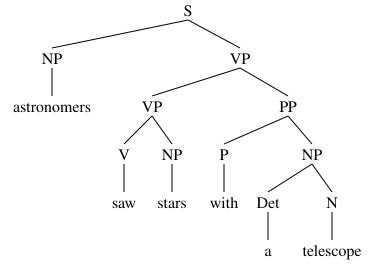

In [4]:
import nltk
from nltk import PCFG

# Define a Probabilistic Context-Free Grammar
# Notice that rules with the same left-hand side have probabilities summing to 1.0
pcfg_grammar = PCFG.fromstring("""
    S -> NP VP          [1.0]
    PP -> P NP          [1.0]

    # VP rules (ambiguous: verb can take a noun phrase, or a noun phrase + prepositional phrase)
    VP -> V NP          [0.4]
    VP -> VP PP         [0.3]
    VP -> V             [0.3]

    # NP rules (ambiguous: noun phrase can be followed by a prepositional phrase)
    NP -> Det N         [0.5]
    NP -> NP PP         [0.2]
    NP -> 'astronomers' [0.1]
    NP -> 'ears'        [0.1]
    NP -> 'stars'       [0.1]

    # Lexical rules with probabilities
    V -> 'saw'          [1.0]
    P -> 'with'         [1.0]
    Det -> 'the'        [0.6]
    Det -> 'a'          [0.4]
    N -> 'telescope'    [0.5]
    N -> 'stars'        [0.5]
""")

# Instantiate a Viterbi Parser which calculates the most likely parse tree using the Viterbi algorithm
viterbi_parser = nltk.ViterbiParser(pcfg_grammar)

# Test sentence (classic syntactic ambiguity: "astronomers saw stars with a telescope")
# Who has the telescope? Is it the astronomers using it to see, or are the stars equipped with a telescope?
sentence = "astronomers saw stars with a telescope"
words = sentence.lower().split()

print(f"Parsing sentence: \"{sentence}\"\n")

# Parse and display the most probable tree
trees = list(viterbi_parser.parse(words))
if trees:
    for tree in trees:
        print(f"Most Probable Parse Tree (Probability: {tree.prob():.6f}):")
        display(tree)
else:
    print("No valid parse found for the sentence under the defined PCFG.")